# Telecom Customer Churn: Analysis and Baseline Prediction System

**Objective.** Identify which telecom customers are likely to leave (churn), understand why, and build a transparent, reproducible baseline (Logistic Regression and K-Nearest Neighbors) evaluated honestly on imbalanced data.

**Dataset.** IBM *Telco Customer Churn* sample dataset.

## Module 1: Problem definition and data understanding
* **Task:** binary classification. **Target:** `Churn` (1 = customer left in the last month). **Unit of observation:** one customer.
* **False positive** (predict churn, customer would have stayed): a retention offer is wasted and margin is given away unnecessarily.
* **False negative** (predict stay, customer leaves): the customer is lost silently; acquiring a replacement usually costs far more than a retention offer. In churn problems a false negative is normally the costlier error.
* **Labeled workflow** (tool used at each stage):


| Stage | Purpose | Tool |
|---|---|---|
| 1 Problem definition | Fix target, unit and error costs | Markdown |
| 2 Data acquisition | Reproducible download of the CSV | pandas |
| 3 Audit and cleaning | Find defects (blanks, types, categories, duplicates) | pandas, NumPy |
| 4 Train/test split | Reserve an untouched 20% test set before any fitting | scikit-learn |
| 5 EDA (train only) | Understand distributions, relationships, hypotheses | Matplotlib, Seaborn, SciPy |
| 6 Preprocess + model | Impute, scale, encode, fit LR and KNN inside pipelines | sklearn Pipeline |
| 7 Evaluate | Confusion matrix, precision, recall, F1, ROC-AUC on test | sklearn.metrics |
| 8 Recommend | Choose threshold by cost, list actions and limits | Report |

* Attribute types: 3 numeric (`tenure`, `MonthlyCharges`, `TotalCharges`), 1 identifier, 16 categorical predictors, 1 target. The data dictionary follows.

## Import Libraries

In [41]:
import os, json, warnings, urllib.request
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
from IPython.display import display
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, cross_val_predict
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             average_precision_score, confusion_matrix, roc_curve, classification_report,
                             ConfusionMatrixDisplay, precision_recall_curve)

warnings.filterwarnings("ignore")
SEED = 42
np.random.seed(SEED)
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)
os.makedirs("figures", exist_ok=True); os.makedirs("outputs", exist_ok=True); os.makedirs("data", exist_ok=True)

def save(name):
    plt.tight_layout()
    plt.savefig(f"figures/{name}.png", dpi=150, bbox_inches="tight")
    plt.show()

DATA_PATH = "/kaggle/input/datasets/aymankhan024/tellco-csv/telco.csv"
if not os.path.exists(DATA_PATH):
    urllib.request.urlretrieve(URL, DATA_PATH)
raw = pd.read_csv(DATA_PATH)
print("Shape:", raw.shape)
display(raw.head())

Shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


### Data dictionary

In [42]:
dictionary = pd.DataFrame([
    ("customerID", "Identifier", "Unique customer ID (dropped before modelling)"),
    ("gender", "Categorical", "Female / Male"),
    ("SeniorCitizen", "Binary (0/1)", "Customer is 65+"),
    ("Partner, Dependents", "Binary", "Has partner / dependents"),
    ("tenure", "Numeric", "Months with the company"),
    ("PhoneService, MultipleLines", "Categorical", "Phone service and multiple lines"),
    ("InternetService", "Categorical", "DSL / Fiber optic / No"),
    ("OnlineSecurity, OnlineBackup, DeviceProtection, TechSupport, StreamingTV, StreamingMovies", "Categorical", "Add-on services"),
    ("Contract", "Categorical (ordinal)", "Month-to-month / One year / Two year"),
    ("PaperlessBilling, PaymentMethod", "Categorical", "Billing preferences"),
    ("MonthlyCharges", "Numeric", "Current monthly bill"),
    ("TotalCharges", "Numeric (stored as text)", "Cumulative amount billed"),
    ("Churn", "Target (Yes/No)", "Customer left within the last month"),
], columns=["Attribute", "Type", "Meaning"])
display(dictionary)

,Attribute,Type,Meaning
0,customerID,Identifier,Unique customer ID (dropped before modelling)
1,gender,Categorical,Female / Male
2,SeniorCitizen,Binary (0/1),Customer is 65+
3,"Partner, Dependents",Binary,Has partner / dependents
4,tenure,Numeric,Months with the company
5,"PhoneService, MultipleLines",Categorical,Phone service and multiple lines
6,InternetService,Categorical,DSL / Fiber optic / No
7,"OnlineSecurity, OnlineBackup, DeviceProtection...",Categorical,Add-on services
8,Contract,Categorical (ordinal),Month-to-month / One year / Two year
9,"PaperlessBilling, PaymentMethod",Categorical,Billing preferences


## Module 2: Statistical and EDA reasoning (concepts used below)
* **Mean** summarizes a typical value but is pulled by extreme or skewed values; **median** is robust to skew; **standard deviation** measures spread around the mean.
* **Distributions** show shape (symmetric, right-skewed, bimodal) and decide which summary and which test (parametric vs rank-based) is appropriate.
* **Outliers** (IQR fences, z-scores) can distort distance-based models such as KNN and the fit of linear models; we check them before deciding to keep, cap or remove.
* **Missingness** must be diagnosed before treatment: here it is *structural* (new customers with tenure 0), not random.
* **Relationships among attributes** (correlation, cross-tabs, Cramér's V) reveal redundancy (tenure vs TotalCharges) and candidate churn drivers.
* **Leakage** (information from the test set or from the future entering training) and **imbalance** (26.5% churners) can make results look better than they are: accuracy hides missed churners, and a feature that encodes the outcome gives useless near-perfect scores. We prevent leakage by splitting first and fitting all learned steps on training data only.
* **Hypotheses to test:** H1 month-to-month customers churn more; H2 short tenure raises churn; H3 higher monthly charges (and fiber optic) raise churn; H4 electronic-check payers churn more.

## Module 3: Data quality investigation
We audit the raw file **before** any modelling: duplicates, missing values, invalid types and inconsistent categories.

In [43]:
audit = {
    "rows": len(raw), "columns": raw.shape[1],
    "fully duplicated rows": int(raw.duplicated().sum()),
    "duplicated customerID": int(raw["customerID"].duplicated().sum()),
    "duplicated feature profiles (ignoring customerID)": int(raw.drop(columns="customerID").duplicated().sum()),
    "NaN cells": int(raw.isna().sum().sum()),
    "blank-string cells": int(raw.select_dtypes("object").apply(lambda s: s.str.strip().eq("")).sum().sum()),
}
display(pd.Series(audit, name="value").to_frame())
print("\nDtypes:"); print(raw.dtypes.value_counts())
print("\nTotalCharges dtype:", raw["TotalCharges"].dtype, "(should be numeric)")
print("SeniorCitizen values:", sorted(raw["SeniorCitizen"].unique()), "(0/1, while other flags use Yes/No)")

,value
rows,7043
columns,21
fully duplicated rows,0
duplicated customerID,0
duplicated feature profiles (ignoring customerID),22
NaN cells,0
blank-string cells,11



Dtypes:
object     18
int64       2
float64     1
Name: count, dtype: int64

TotalCharges dtype: object (should be numeric)
SeniorCitizen values: [np.int64(0), np.int64(1)] (0/1, while other flags use Yes/No)


**Findings so far**
* No fully duplicated rows and no duplicated `customerID`. 22 rows share an identical feature profile with another customer; since IDs differ they are distinct customers, so they are **kept** (but we measure the leakage risk they create after the split).
* `TotalCharges` is stored as text because 11 cells are blank strings (hidden missing values, `isna()` reports 0).
* `SeniorCitizen` is coded 0/1 while all other flags use Yes/No (inconsistent format).

In [44]:
print("Categories per text column:\n")
for c in raw.select_dtypes("object").columns:
    if c in ("customerID", "TotalCharges"): continue
    ws = int((raw[c] != raw[c].str.strip()).sum())
    print(f"{c:18s} {sorted(raw[c].unique())}  whitespace issues: {ws}")
print("\nRows with blank TotalCharges:")
display(raw[raw["TotalCharges"].str.strip() == ""][["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Churn"]])

Categories per text column:

gender             ['Female', 'Male']  whitespace issues: 0
Partner            ['No', 'Yes']  whitespace issues: 0
Dependents         ['No', 'Yes']  whitespace issues: 0
PhoneService       ['No', 'Yes']  whitespace issues: 0
MultipleLines      ['No', 'No phone service', 'Yes']  whitespace issues: 0
InternetService    ['DSL', 'Fiber optic', 'No']  whitespace issues: 0
OnlineSecurity     ['No', 'No internet service', 'Yes']  whitespace issues: 0
OnlineBackup       ['No', 'No internet service', 'Yes']  whitespace issues: 0
DeviceProtection   ['No', 'No internet service', 'Yes']  whitespace issues: 0
TechSupport        ['No', 'No internet service', 'Yes']  whitespace issues: 0
StreamingTV        ['No', 'No internet service', 'Yes']  whitespace issues: 0
StreamingMovies    ['No', 'No internet service', 'Yes']  whitespace issues: 0
Contract           ['Month-to-month', 'One year', 'Two year']  whitespace issues: 0
PaperlessBilling   ['No', 'Yes']  whitespace issu

,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,,No
753,3115-CZMZD,0,20.25,,No
936,5709-LVOEQ,0,80.85,,No
1082,4367-NUYAO,0,25.75,,No
1340,1371-DWPAZ,0,56.05,,No
3331,7644-OMVMY,0,19.85,,No
3826,3213-VVOLG,0,25.35,,No
4380,2520-SGTTA,0,20.00,,No
5218,2923-ARZLG,0,19.70,,No
6670,4075-WKNIU,0,73.35,,No


**Inconsistent / redundant categories.** Six add-on columns use *"No internet service"* and `MultipleLines` uses *"No phone service"*. These carry the same information as `InternetService == "No"` and `PhoneService == "No"`, so merging them into "No" removes redundancy without losing information. The 11 blank `TotalCharges` rows all have `tenure == 0` (brand-new customers not yet billed), and none of them churned.

In [45]:
ADDON = ["OnlineSecurity", "OnlineBackup", "DeviceProtection", "TechSupport", "StreamingTV", "StreamingMovies"]

def clean(df):
    """Deterministic, rule-based cleaning (nothing is learned from data, so it is safe before the split)."""
    d = df.copy()
    for c in d.select_dtypes("object"):
        d[c] = d[c].str.strip()
    d["TotalCharges"] = pd.to_numeric(d["TotalCharges"], errors="coerce")
    d[ADDON] = d[ADDON].replace("No internet service", "No")     
    d["MultipleLines"] = d["MultipleLines"].replace("No phone service", "No")  
    d["SeniorCitizen"] = d["SeniorCitizen"].map({0: "No", 1: "Yes"})
    d["Churn"] = d["Churn"].map({"No": 0, "Yes": 1}).astype(int)
    return d

df = clean(raw)
print("Missing after cleaning:\n", df.isna().sum()[lambda s: s > 0])
print("\nTotalCharges NaN rows all have tenure == 0:", bool((df.loc[df.TotalCharges.isna(), "tenure"] == 0).all()),
      "| churn among them:", int(df.loc[df.TotalCharges.isna(), "Churn"].sum()))
print("Check: is TotalCharges ~ tenure*MonthlyCharges?  corr =",
      round(df[["TotalCharges"]].assign(prod=df.tenure * df.MonthlyCharges).corr().iloc[0, 1], 3))

Missing after cleaning:
 TotalCharges    11
dtype: int64

TotalCharges NaN rows all have tenure == 0: True | churn among them: 0
Check: is TotalCharges ~ tenure*MonthlyCharges?  corr = 1.0


### Cleaning function and the missing-value diagnosis
`clean()` only applies **deterministic rules** (type conversion, category merging, label encoding). Nothing is learned from the data, so it is safe to run before the split. Learned steps (imputation, scaling, encoding, feature selection, K, thresholds) happen **after** the split and use the training set only.

In [46]:
NUM = ["tenure", "MonthlyCharges", "TotalCharges"]
CAT = [c for c in df.columns if c not in NUM + ["customerID", "Churn"]]
X = df.drop(columns=["customerID", "Churn"]); y = df["Churn"]

# SPLIT FIRST: everything learned from data (imputer, scaler, encoder, feature selection, K, thresholds) uses X_train only.
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
print(f"Train {X_train.shape}, Test {X_test.shape}")
print(f"Churn rate  full={y.mean():.3f}  train={y_train.mean():.3f}  test={y_test.mean():.3f}")
key = lambda d: d.apply(lambda r: "|".join(map(str, r.values)), axis=1)
overlap = key(X_test).isin(set(key(X_train))).mean()
print(f"Share of test rows whose exact feature profile also appears in train (duplicate-profile leakage risk): {overlap:.3%}")

eda = X_train.assign(Churn=y_train)   

Train (5634, 19), Test (1409, 19)
Churn rate  full=0.265  train=0.265  test=0.265
Share of test rows whose exact feature profile also appears in train (duplicate-profile leakage risk): 0.923%


### Train/test split (leakage prevention)
Stratified 80/20 split so both sets keep the same churn rate. The test set is touched **once**, at the end.

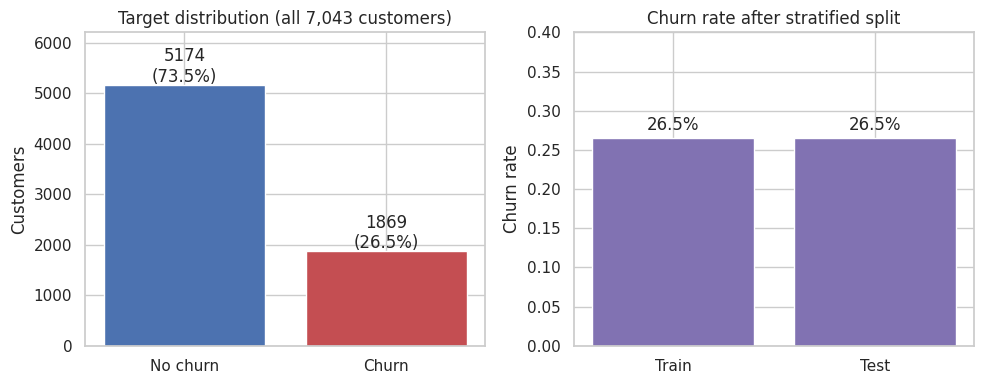

A model that always predicts 'No churn' scores accuracy = 0.735


In [47]:
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
cnt = y.value_counts().sort_index()
ax[0].bar(["No churn", "Churn"], cnt.values, color=["#4C72B0", "#C44E52"])
for i, v in enumerate(cnt.values):
    ax[0].text(i, v + 60, f"{v}\n({v/len(y):.1%})", ha="center")
ax[0].set_title("Target distribution (all 7,043 customers)"); ax[0].set_ylabel("Customers"); ax[0].set_ylim(0, cnt.max() * 1.2)
ax[1].bar(["Train", "Test"], [y_train.mean(), y_test.mean()], color="#8172B2")
ax[1].set_ylim(0, 0.4); ax[1].set_title("Churn rate after stratified split"); ax[1].set_ylabel("Churn rate")
for i, v in enumerate([y_train.mean(), y_test.mean()]): ax[1].text(i, v + .01, f"{v:.1%}", ha="center")
save("fig1_target_distribution")
print("A model that always predicts 'No churn' scores accuracy =", round(1 - y.mean(), 3))

## Module 4: Exploratory data analysis and visual evidence (training data only)
### Target distribution
About 26.5% of customers churn, so the data are **imbalanced**. A model that always predicts "stay" is 73.5% accurate while catching zero churners, which is why accuracy alone is not enough.

### Descriptive statistics
* `tenure` and `MonthlyCharges` are roughly symmetric (|skew| < 0.3); `TotalCharges` is right-skewed (0.95), so its mean (2,303) is well above its median (1,398).
* Churners have much shorter tenure (median 10 vs 38 months) and higher monthly bills (median 79.95 vs 64.40). Because medians are robust to skew, they are the better summary here.

In [48]:
desc = eda[NUM].describe().T
desc["skew"] = eda[NUM].skew()
display(desc.round(2))
print("\nMedian / mean by churn status:")
display(eda.groupby("Churn")[NUM].agg(["mean", "median", "std"]).round(2))

,count,mean,std,min,25%,50%,75%,max,skew
tenure,5634.0,32.49,24.57,0.00,9.00,29.00,55.00,72.00,0.24
MonthlyCharges,5634.0,64.93,30.14,18.40,35.66,70.50,90.00,118.75,-0.22
TotalCharges,5626.0,2302.60,2279.17,18.85,407.28,1398.12,3838.61,8684.80,0.95



Median / mean by churn status:


tenure               MonthlyCharges               TotalCharges                 
        mean median    std           mean median    std         mean  median      std
Churn                                                                                
0      37.59   38.0  24.14          61.34  64.40  31.14      2569.69  1691.9  2342.74
1      18.36   10.0  19.74          74.86  79.95  24.60      1564.59   740.3  1908.84

### Numeric distributions by churn

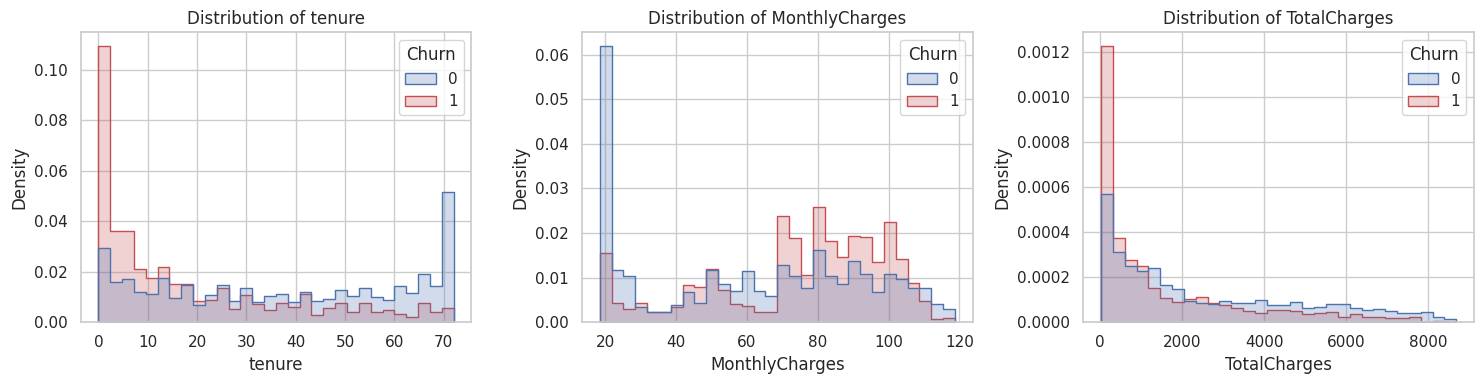

In [49]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for a, c in zip(ax, NUM):
    sns.histplot(data=eda, x=c, hue="Churn", bins=30, stat="density", common_norm=False, element="step", ax=a,
                 palette={0: "#4C72B0", 1: "#C44E52"})
    a.set_title(f"Distribution of {c}")
save("fig2_numeric_distributions")

### Churn rate across categorical groups
Month-to-month contracts, fiber optic internet, electronic-check payment and no tech support all show churn rates far above the 26.5% average (dashed line). These are **associations**, not proof of cause.

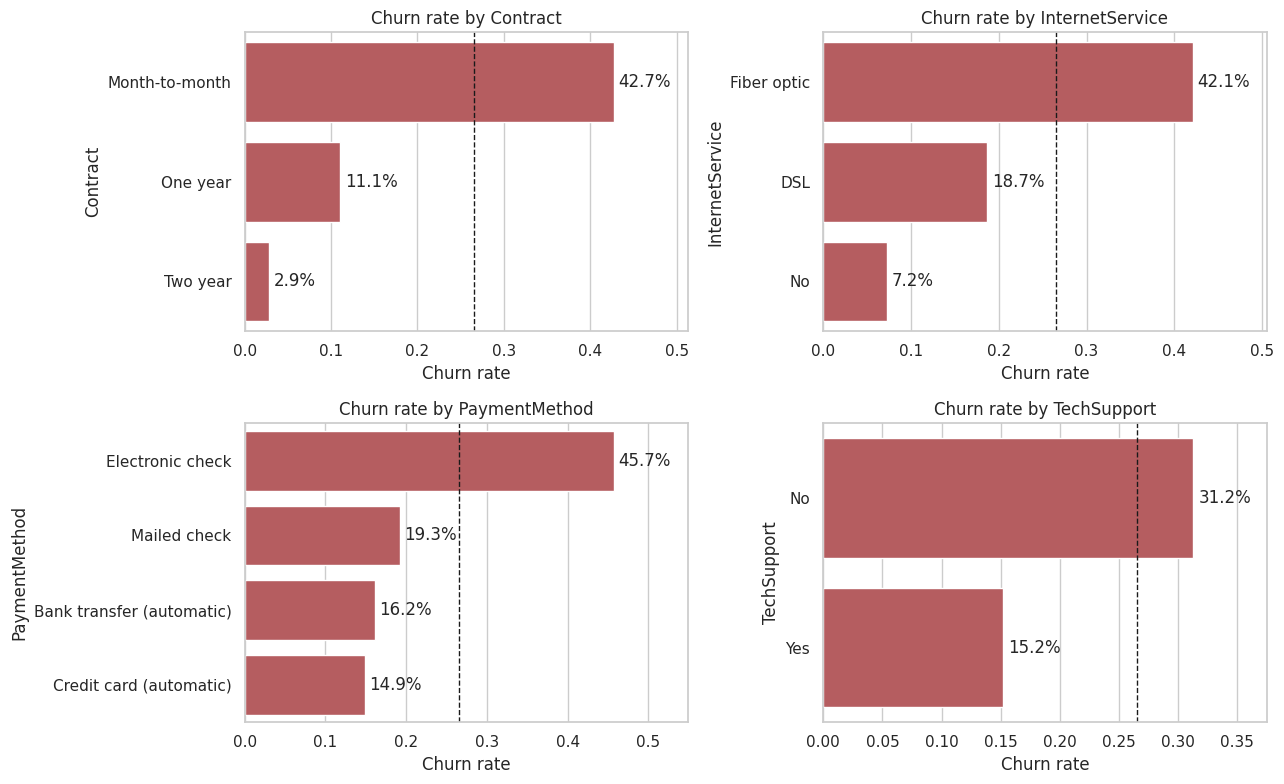

Dashed line = overall training churn rate: 0.265


In [50]:
cols = ["Contract", "InternetService", "PaymentMethod", "TechSupport"]
fig, ax = plt.subplots(2, 2, figsize=(13, 8))
base = eda.Churn.mean()
for a, c in zip(ax.ravel(), cols):
    r = eda.groupby(c).Churn.mean().sort_values(ascending=False)
    sns.barplot(x=r.values, y=r.index, ax=a, color="#C44E52")
    a.axvline(base, color="k", ls="--", lw=1); a.set_xlabel("Churn rate"); a.set_title(f"Churn rate by {c}")
    for i, v in enumerate(r.values): a.text(v + .005, i, f"{v:.1%}", va="center")
    a.set_xlim(0, max(r.values) * 1.2)
save("fig3_categorical_churn_rates")
print("Dashed line = overall training churn rate:", round(base, 3))

### Outlier assessment
No value falls outside the 1.5xIQR fences or |z| > 3 in any numeric column (table below), so no outlier removal or capping is needed. Extreme values would matter for KNN (distance based) and, to a lesser degree, for LR."

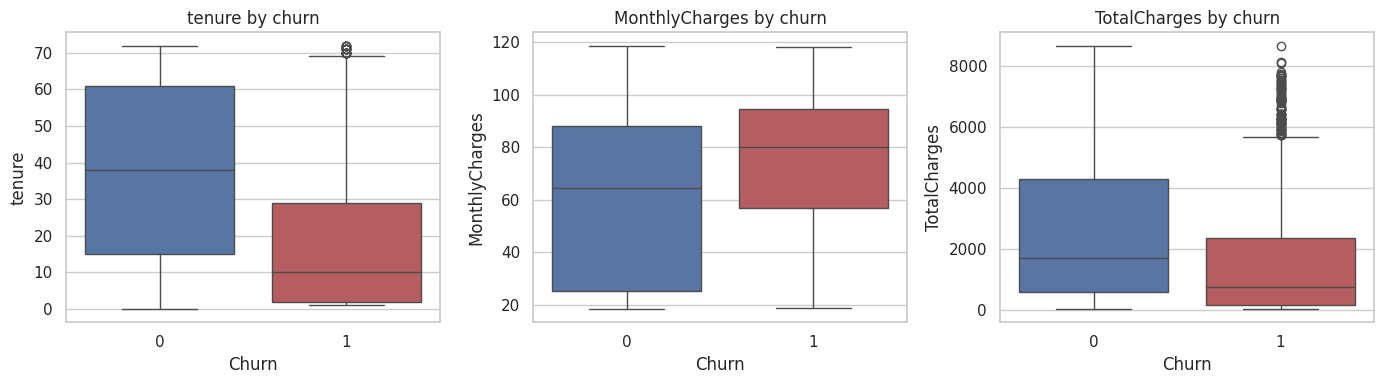

,feature,IQR outliers,lower fence,upper fence,|z|>3
0,tenure,0,-60.0,124.0,0
1,MonthlyCharges,0,-45.8,171.5,0
2,TotalCharges,0,-4739.7,8985.6,0


In [51]:
fig, ax = plt.subplots(1, 3, figsize=(14, 4))
for a, c in zip(ax, NUM):
    sns.boxplot(data=eda, x="Churn", y=c, hue="Churn", ax=a, palette=["#4C72B0", "#C44E52"], legend=False)
    a.set_title(f"{c} by churn")
save("fig4_outlier_boxplots")
rows = []
for c in NUM:
    s = eda[c].dropna(); q1, q3 = s.quantile([.25, .75]); iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    rows.append((c, int(((s < lo) | (s > hi)).sum()), round(lo, 1), round(hi, 1), int((np.abs(stats.zscore(s)) > 3).sum())))
outl = pd.DataFrame(rows, columns=["feature", "IQR outliers", "lower fence", "upper fence", "|z|>3"])
display(outl)

### Feature relationships

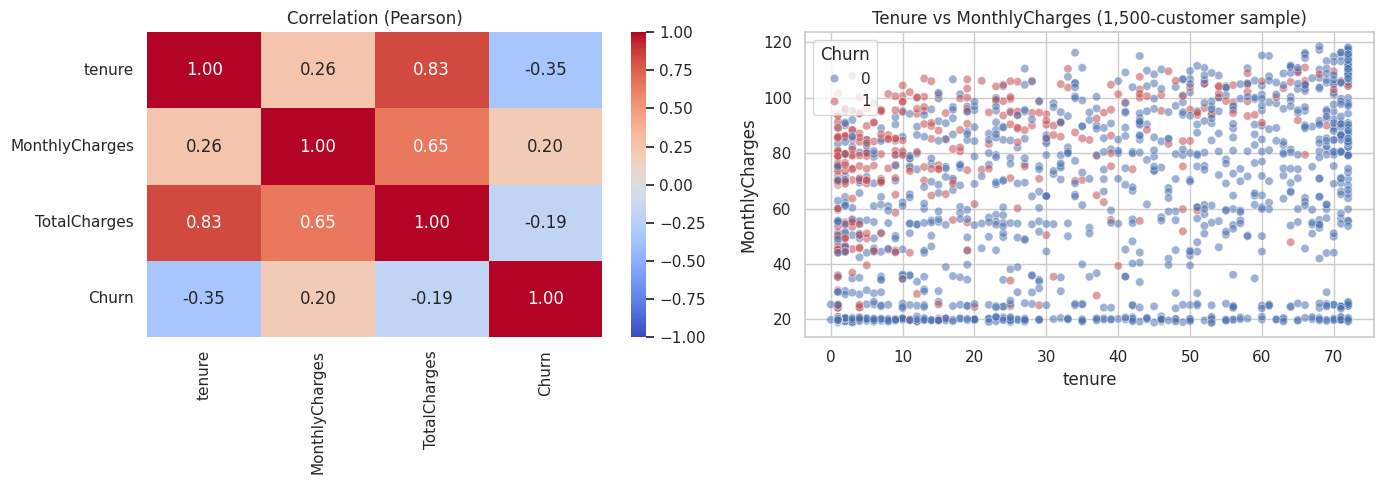

In [52]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
corr = eda[NUM + ["Churn"]].corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=ax[0]); ax[0].set_title("Correlation (Pearson)")
samp = eda.sample(1500, random_state=SEED)
sns.scatterplot(data=samp, x="tenure", y="MonthlyCharges", hue="Churn", alpha=.55, ax=ax[1], palette={0: "#4C72B0", 1: "#C44E52"})
ax[1].set_title("Tenure vs MonthlyCharges (1,500-customer sample)")
save("fig5_feature_relationships")

### Interaction of tenure and contract


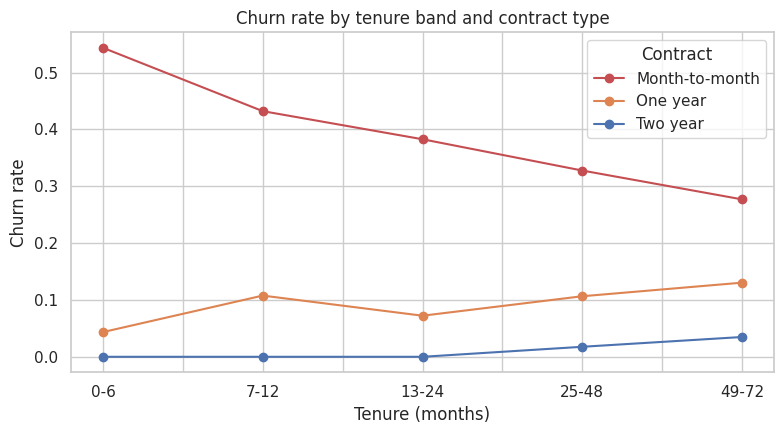

Contract,Month-to-month,One year,Two year
tenure_band,,,
0-6,0.544,0.043,0.000
7-12,0.432,0.108,0.000
13-24,0.383,0.072,0.000
25-48,0.328,0.107,0.018
49-72,0.277,0.130,0.035


In [53]:
eda["tenure_band"] = pd.cut(eda.tenure, [-1, 6, 12, 24, 48, 72], labels=["0-6", "7-12", "13-24", "25-48", "49-72"])
pt = eda.pivot_table(index="tenure_band", columns="Contract", values="Churn", aggfunc="mean")
ax = pt.plot(marker="o", figsize=(8, 4.5), color=["#C44E52", "#DD8452", "#4C72B0"])
ax.set_ylabel("Churn rate"); ax.set_title("Churn rate by tenure band and contract type"); ax.set_xlabel("Tenure (months)")
save("fig6_tenure_contract")
display(pt.round(3))

In [54]:
def cramers_v(a, b):
    ct = pd.crosstab(a, b); chi2, p, _, _ = stats.chi2_contingency(ct)
    return np.sqrt(chi2 / (ct.values.sum() * (min(ct.shape) - 1))), p

assoc = pd.DataFrame([(c, *cramers_v(eda[c], eda.Churn)) for c in CAT], columns=["feature", "cramers_v", "p_value"])
assoc = assoc.sort_values("cramers_v", ascending=False).reset_index(drop=True)
alpha_bonf = 0.05 / len(CAT)
assoc["significant (Bonferroni)"] = assoc.p_value < alpha_bonf
display(assoc.round(4))

num_tests = []
for c in NUM:
    a, b = eda.loc[eda.Churn == 1, c].dropna(), eda.loc[eda.Churn == 0, c].dropna()
    u, p = stats.mannwhitneyu(a, b)
    num_tests.append((c, a.median(), b.median(), p, 2 * u / (len(a) * len(b)) - 1))
num_tests = pd.DataFrame(num_tests, columns=["feature", "median churned", "median retained", "p_value", "rank_biserial"])
display(num_tests.round(4))

,feature,cramers_v,p_value,significant (Bonferroni)
0,Contract,0.4111,0.0000,True
1,InternetService,0.3266,0.0000,True
2,PaymentMethod,0.3111,0.0000,True
3,PaperlessBilling,0.1976,0.0000,True
4,OnlineSecurity,0.1741,0.0000,True
5,Dependents,0.1670,0.0000,True
6,TechSupport,0.1653,0.0000,True
7,Partner,0.1453,0.0000,True
8,SeniorCitizen,0.1451,0.0000,True
9,OnlineBackup,0.0820,0.0000,True


,feature,median churned,median retained,p_value,rank_biserial
0,tenure,10.00,38.0,0.0,-0.4704
1,MonthlyCharges,79.95,64.4,0.0,0.2479
2,TotalCharges,740.30,1691.9,0.0,-0.2934


* **H1:** month-to-month customers churn more than contracted customers (Cramér's V = 0.41, the strongest categorical effect).
* **H2:** churners have shorter tenure (Mann-Whitney p < 0.001, rank-biserial r = -0.47, medium-large).
* **H3:** higher monthly charges go with churn (p < 0.001, r = 0.25, small-medium). Fiber optic and electronic-check customers (H4) also churn more.

Significance is judged with a Bonferroni-corrected alpha (0.05/16) because 16 categorical tests are run. With n = 5,634 even tiny effects are "significant", so we also report effect sizes. **What the plots cannot show:** why customers leave (price, service quality, competitor offers, or unmeasured factors), or whether changing a variable would change churn.

### Association strength; basis for feature selection

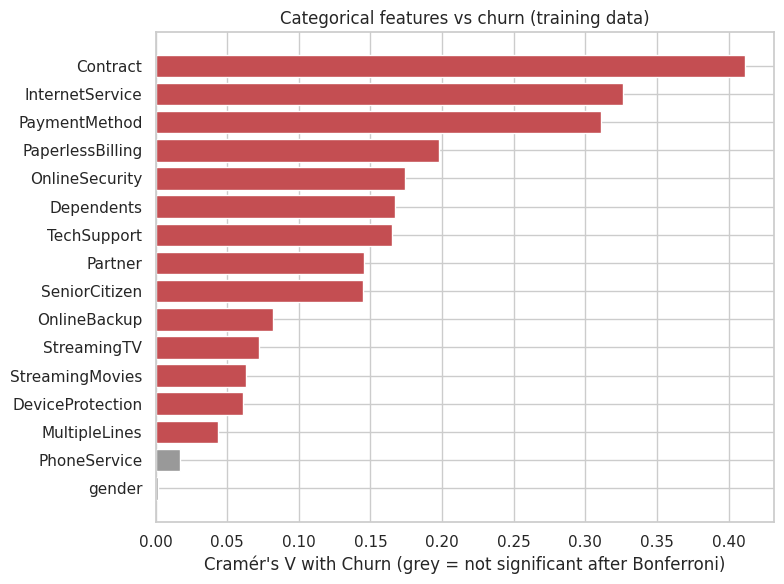

In [55]:
fig, ax = plt.subplots(figsize=(8, 6))
a2 = assoc.sort_values("cramers_v")
ax.barh(a2.feature, a2.cramers_v, color=np.where(a2["significant (Bonferroni)"], "#C44E52", "#999999"))
ax.set_xlabel("Cramér's V with Churn (grey = not significant after Bonferroni)"); ax.set_title("Categorical features vs churn (training data)")
save("fig7_feature_association")

In [56]:
skf = StratifiedKFold(5, shuffle=True, random_state=SEED)
SCORING = {"roc_auc": "roc_auc", "f1": "f1", "recall": "recall", "precision": "precision"}

def make_pre(num, cat, impute="median", scale=True):
    steps = [("imp", SimpleImputer(strategy=impute))] + ([("sc", StandardScaler())] if scale else [])
    return ColumnTransformer([("num", Pipeline(steps), num),
                              ("cat", OneHotEncoder(handle_unknown="ignore", drop="if_binary"), cat)])

def cv_eval(model, Xd, yd, num=NUM, cat=CAT, **kw):
    pipe = Pipeline([("pre", make_pre(num, cat, **kw)), ("clf", model)])
    r = cross_validate(pipe, Xd, yd, cv=skf, scoring=SCORING)
    return {k: r[f"test_{k}"].mean() for k in SCORING}

lr = lambda **k: LogisticRegression(max_iter=2000, random_state=SEED, **k)
mask = X_train.TotalCharges.notna()
variants = {
    "A: drop 11 rows with missing TotalCharges": (X_train[mask], y_train[mask], "median"),
    "B: median imputation (fit inside CV folds)": (X_train, y_train, "median"),
    "C: fill with 0 (tenure = 0, nothing billed yet)": (X_train.fillna({"TotalCharges": 0}), y_train, "median"),
}
res = {}
for name, (Xd, yd, imp) in variants.items():
    res[name] = {"rows used": len(Xd), "TotalCharges mean": Xd.TotalCharges.mean(), "TotalCharges median": Xd.TotalCharges.median(),
                 **cv_eval(lr(), Xd, yd, impute=imp)}
treat = pd.DataFrame(res).T
display(treat.round(4))
treat.to_csv("outputs/treatment_missing_values.csv")

,rows used,TotalCharges mean,TotalCharges median,roc_auc,f1,recall,precision
A: drop 11 rows with missing TotalCharges,5626.0,2302.6043,1398.125,0.8454,0.5958,0.5465,0.6561
B: median imputation (fit inside CV folds),5634.0,2302.6043,1398.125,0.8461,0.5929,0.5438,0.6534
"C: fill with 0 (tenure = 0, nothing billed yet)",5634.0,2299.3347,1394.925,0.8461,0.5926,0.5431,0.6536


## Compare defensible treatment choices
### Treatment 1: missing `TotalCharges` (11 rows, all `tenure == 0`)
Three options are compared using 5-fold cross-validation on the training set. Imputation is inside the CV pipeline, so it is fitted on training folds only. **Result:** differences are negligible (AUC 0.845 vs 0.846, F1 0.593-0.596). We choose **C/B-style imputation inside the pipeline** (keeps all rows; zero or median is justified because these customers have not been billed). Dropping rows would also be fine, but discards genuine, valid customers.

### Treatment 2: scaling

In [57]:
rows = []
for scale in (False, True):
    rows.append(("Logistic Regression", scale, *cv_eval(lr(), X_train, y_train, scale=scale).values()))
    rows.append(("KNN (K=15)", scale, *cv_eval(KNeighborsClassifier(15), X_train, y_train, scale=scale).values()))
scal = pd.DataFrame(rows, columns=["model", "scaled", *SCORING.keys()])
display(scal.round(4))
scal.to_csv("outputs/treatment_scaling.csv", index=False)

,model,scaled,roc_auc,f1,recall,precision
0,Logistic Regression,False,0.8460,0.5927,0.5438,0.6529
1,KNN (K=15),False,0.7826,0.4931,0.3993,0.6453
2,Logistic Regression,True,0.8461,0.5929,0.5438,0.6534
3,KNN (K=15),True,0.8243,0.5851,0.5565,0.6172


Scaling does nothing for Logistic Regression (AUC 0.846 either way; it only changes coefficient scale and optimiser speed) but is **essential for KNN**: AUC rises from 0.783 to 0.824 and F1 from 0.494 to 0.585, because unscaled `TotalCharges` (up to ~8,700) would dominate the distance.

### Feature selection (justified with training data only)

In [58]:
SEL_CAT = assoc.loc[assoc["significant (Bonferroni)"], "feature"].tolist()
DROPPED_CAT = [c for c in CAT if c not in SEL_CAT]
print("Dropped (no significant association with churn):", DROPPED_CAT)
print("tenure vs TotalCharges correlation:", round(eda[["tenure", "TotalCharges"]].corr().iloc[0, 1], 3))

sets = {"ALL features": (NUM, CAT),
        "Selected (drop non-significant)": (NUM, SEL_CAT),
        "Selected, without TotalCharges": (["tenure", "MonthlyCharges"], SEL_CAT)}
rows = []
for name, (n, c) in sets.items():
    m_lr = cv_eval(lr(), X_train, y_train, n, c); m_kn = cv_eval(KNeighborsClassifier(15), X_train, y_train, n, c)
    rows.append((name, len(n) + len(c), m_lr["roc_auc"], m_lr["f1"], m_kn["roc_auc"], m_kn["f1"]))
fs = pd.DataFrame(rows, columns=["feature set", "n raw features", "LR AUC", "LR F1", "KNN AUC", "KNN F1"])
display(fs.round(4)); fs.to_csv("outputs/feature_selection.csv", index=False)
best = fs["LR AUC"].max()
chosen = fs[fs["LR AUC"] >= best - 0.002].sort_values("n raw features").iloc[0]["feature set"]
NUMF, CATF = sets[chosen]
print("\nChosen feature set:", chosen, "->", NUMF + CATF)

Dropped (no significant association with churn): ['gender', 'PhoneService']
tenure vs TotalCharges correlation: 0.829


,feature set,n raw features,LR AUC,LR F1,KNN AUC,KNN F1
0,ALL features,19,0.8461,0.5929,0.8243,0.5851
1,Selected (drop non-significant),17,0.8464,0.5939,0.8211,0.5842
2,"Selected, without TotalCharges",16,0.8452,0.5895,0.8211,0.5815



Chosen feature set: Selected, without TotalCharges -> ['tenure', 'MonthlyCharges', 'Contract', 'InternetService', 'PaymentMethod', 'PaperlessBilling', 'OnlineSecurity', 'Dependents', 'TechSupport', 'Partner', 'SeniorCitizen', 'OnlineBackup', 'StreamingTV', 'StreamingMovies', 'DeviceProtection', 'MultipleLines']


Features with no significant association with churn after Bonferroni correction (`gender`, `PhoneService`) are removed. We also test dropping `TotalCharges` (redundant with tenure x MonthlyCharges). CV performance is practically identical for all three sets (LR AUC 0.845-0.846), so by parsimony we keep the **smallest set within 0.002 AUC of the best**: 16 features, without `TotalCharges`, `gender`, `PhoneService`.

## Module 5: Predictive modelling

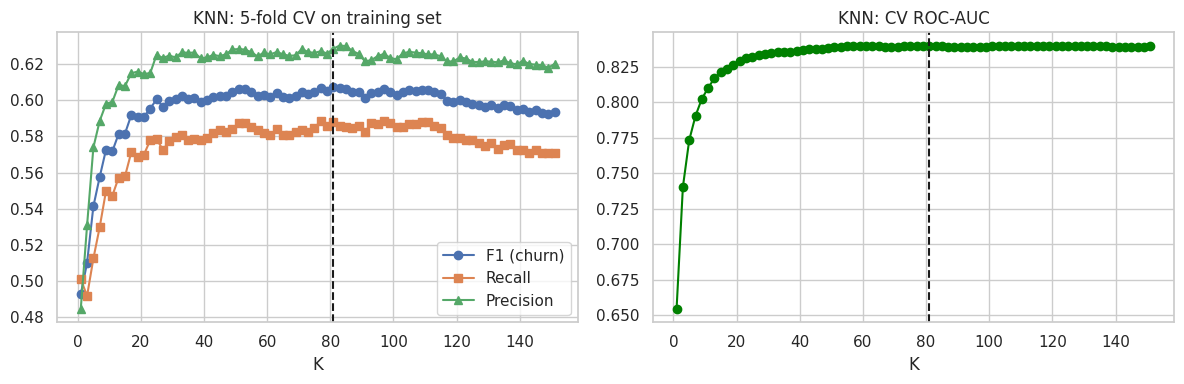

Best K by CV F1: 81 | best K by CV AUC: 59


,K,roc_auc,f1,recall,precision
0,1,0.6542,0.4925,0.5010,0.4843
2,5,0.7733,0.5413,0.5124,0.5739
5,11,0.8102,0.5717,0.5472,0.5991
10,21,0.8295,0.5908,0.5699,0.6146
15,31,0.8347,0.6007,0.5799,0.6238
25,51,0.8390,0.6064,0.5873,0.6284
35,71,0.8392,0.6046,0.5833,0.6285
40,81,0.8398,0.6072,0.5880,0.6286
50,101,0.8394,0.6030,0.5853,0.6227
75,151,0.8394,0.5934,0.5706,0.6202


In [59]:
# Choose K for KNN by cross-validation on the training set 
Ks = list(range(1, 152, 2)); rows = []
for k in Ks:
    m = cv_eval(KNeighborsClassifier(k), X_train, y_train, NUMF, CATF)
    rows.append((k, m["roc_auc"], m["f1"], m["recall"], m["precision"]))
kdf = pd.DataFrame(rows, columns=["K", "roc_auc", "f1", "recall", "precision"])
K_BEST = int(kdf.loc[kdf.f1.idxmax(), "K"])
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(kdf.K, kdf.f1, marker="o", label="F1 (churn)"); ax[0].plot(kdf.K, kdf.recall, marker="s", label="Recall"); ax[0].plot(kdf.K, kdf.precision, marker="^", label="Precision")
ax[0].axvline(K_BEST, color="k", ls="--"); ax[0].set_xlabel("K"); ax[0].legend(); ax[0].set_title("KNN: 5-fold CV on training set")
ax[1].plot(kdf.K, kdf.roc_auc, marker="o", color="green"); ax[1].axvline(K_BEST, color="k", ls="--"); ax[1].set_xlabel("K"); ax[1].set_title("KNN: CV ROC-AUC")
save("fig8_knn_k_selection")
print("Best K by CV F1:", K_BEST, "| best K by CV AUC:", int(kdf.loc[kdf.roc_auc.idxmax(), 'K']))
display(kdf[kdf.K.isin([1, 5, 11, 21, 31, 51, 71, 101, 151, K_BEST])].round(4))
kdf.to_csv("outputs/knn_k_search.csv", index=False)

### Choosing K for KNN
K is tuned by 5-fold CV on the training set (not the test set). K = 1 overfits badly (AUC 0.65). Performance rises and then plateaus between about K = 25 and 121 (CV F1 about 0.60-0.61). We take the maximum, **K = 81**, but note the curve is flat, so nearby values behave the same.

### Training, thresholds and held-out test evaluation

In [60]:
def pipe(model): return Pipeline([("pre", make_pre(NUMF, CATF)), ("clf", model)])
models = {
    "Majority-class baseline": pipe(DummyClassifier(strategy="most_frequent")),
    "Logistic Regression": pipe(lr()),
    "Logistic Regression (balanced)": pipe(lr(class_weight="balanced")),
    f"KNN (K={K_BEST})": pipe(KNeighborsClassifier(K_BEST)),
}
for m in models.values(): m.fit(X_train, y_train)
proba = {n: m.predict_proba(X_test)[:, 1] for n, m in models.items()}

oof = {n: cross_val_predict(pipe(KNeighborsClassifier(K_BEST) if n.startswith("KNN") else lr(class_weight="balanced" if "balanced" in n else None)),
                            X_train, y_train, cv=skf, method="predict_proba")[:, 1]
       for n in models if n != "Majority-class baseline"}
def recall_threshold(p, target=0.80):
    prec, rec, thr = precision_recall_curve(y_train, p)
    ok = np.where(rec[:-1] >= target)[0]
    return float(thr[ok[-1]]) if len(ok) else 0.0
thr_rec = {n: recall_threshold(p) for n, p in oof.items()}
print("Recall>=0.80 thresholds (from OOF train predictions):", {k: round(v, 3) for k, v in thr_rec.items()})

def metrics(name, p, thr=0.5):
    pred = (p >= thr).astype(int); tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    return {"model": name, "threshold": round(thr, 3), "accuracy": accuracy_score(y_test, pred),
            "precision": precision_score(y_test, pred, zero_division=0), "recall": recall_score(y_test, pred),
            "f1": f1_score(y_test, pred), "roc_auc": roc_auc_score(y_test, p), "pr_auc": average_precision_score(y_test, p),
            "TP": tp, "FP": fp, "FN": fn, "TN": tn}
rows = [metrics(n, p) for n, p in proba.items()]
for n in thr_rec:
    rows.append(metrics(n + " @ recall>=0.80 threshold", proba[n], thr_rec[n]))
results = pd.DataFrame(rows)
display(results.round(3)); results.to_csv("outputs/model_comparison.csv", index=False)

Recall>=0.80 thresholds (from OOF train predictions): {'Logistic Regression': 0.255, 'Logistic Regression (balanced)': 0.495, 'KNN (K=81)': 0.309}


,model,threshold,accuracy,precision,recall,f1,roc_auc,pr_auc,TP,FP,FN,TN
0,Majority-class baseline,0.500,0.735,0.000,0.000,0.000,0.500,0.265,0,0,374,1035
1,Logistic Regression,0.500,0.798,0.639,0.545,0.589,0.839,0.630,204,115,170,920
2,Logistic Regression (balanced),0.500,0.742,0.509,0.778,0.615,0.839,0.629,291,281,83,754
3,KNN (K=81),0.500,0.781,0.588,0.583,0.585,0.833,0.615,218,153,156,882
4,Logistic Regression @ recall>=0.80 threshold,0.255,0.734,0.499,0.783,0.610,0.839,0.630,293,294,81,741
5,Logistic Regression (balanced) @ recall>=0.80 ...,0.495,0.738,0.504,0.778,0.612,0.839,0.629,291,286,83,749
6,KNN (K=81) @ recall>=0.80 threshold,0.309,0.734,0.499,0.805,0.616,0.833,0.615,301,302,73,733


Default threshold 0.5 is rarely right for imbalanced data. The "recall >= 0.80" operating thresholds are chosen from **out-of-fold training predictions**, never from the test set.

### Confusion matrices, ROC and precision-recall curves

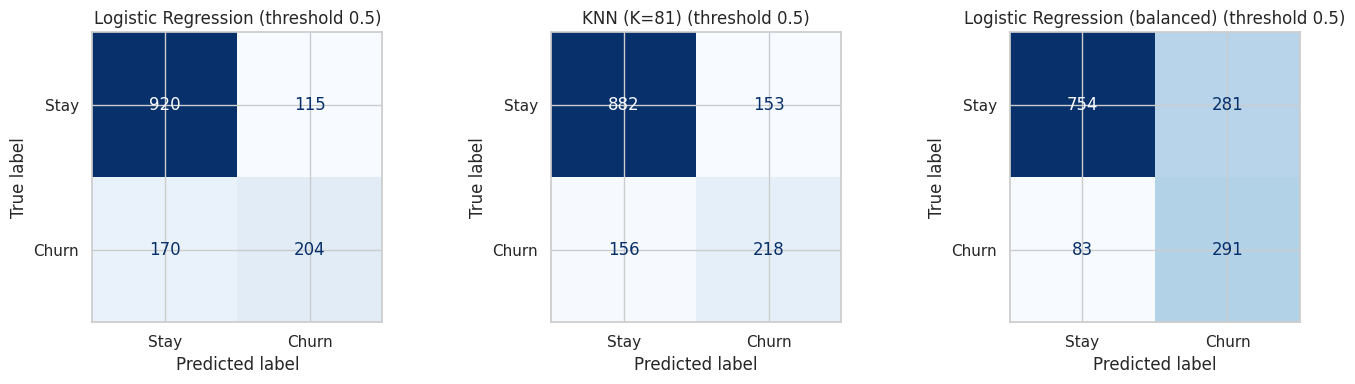

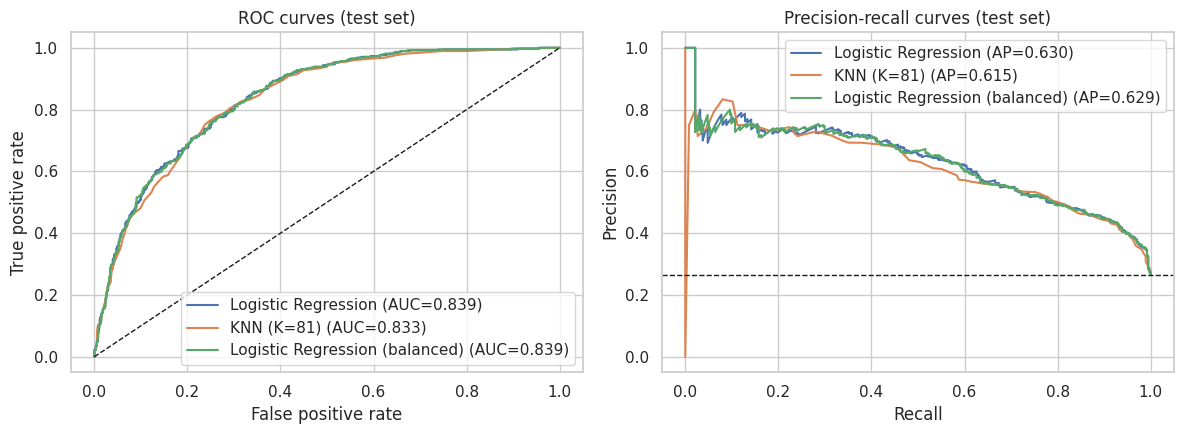

In [61]:
show = ["Logistic Regression", f"KNN (K={K_BEST})", "Logistic Regression (balanced)"]
fig, ax = plt.subplots(1, 3, figsize=(14, 4))
for a, n in zip(ax, show):
    ConfusionMatrixDisplay.from_predictions(y_test, (proba[n] >= .5).astype(int), display_labels=["Stay", "Churn"], cmap="Blues", ax=a, colorbar=False)
    a.set_title(n + " (threshold 0.5)")
save("fig9_confusion_matrices")

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
for n in show:
    f, t, _ = roc_curve(y_test, proba[n]); ax[0].plot(f, t, label=f"{n} (AUC={roc_auc_score(y_test, proba[n]):.3f})")
    p_, r_, _ = precision_recall_curve(y_test, proba[n]); ax[1].plot(r_, p_, label=f"{n} (AP={average_precision_score(y_test, proba[n]):.3f})")
ax[0].plot([0, 1], [0, 1], "k--", lw=1); ax[0].set_xlabel("False positive rate"); ax[0].set_ylabel("True positive rate"); ax[0].set_title("ROC curves (test set)"); ax[0].legend(loc="lower right")
ax[1].axhline(y_test.mean(), color="k", ls="--", lw=1); ax[1].set_xlabel("Recall"); ax[1].set_ylabel("Precision"); ax[1].set_title("Precision-recall curves (test set)"); ax[1].legend()
save("fig10_roc_pr_curves")

### Uncertainty: bootstrap 95% confidence intervals (test set)

In [62]:
rng = np.random.default_rng(SEED); B = 1000; yt = y_test.values; n = len(yt)
pl, pk = proba["Logistic Regression"], proba[f"KNN (K={K_BEST})"]
auc_l, auc_k, rec_l, rec_k = [], [], [], []
for _ in range(B):
    i = rng.integers(0, n, n)
    if yt[i].min() == yt[i].max(): continue
    auc_l.append(roc_auc_score(yt[i], pl[i])); auc_k.append(roc_auc_score(yt[i], pk[i]))
    rec_l.append(recall_score(yt[i], pl[i] >= .5)); rec_k.append(recall_score(yt[i], pk[i] >= .5))
ci = lambda a: (np.percentile(a, 2.5), np.percentile(a, 97.5))
boot = pd.DataFrame({"LR AUC": ci(auc_l), "KNN AUC": ci(auc_k), "AUC diff (LR-KNN)": ci(np.array(auc_l) - np.array(auc_k)),
                     "LR recall": ci(rec_l), "KNN recall": ci(rec_k)}, index=["2.5%", "97.5%"]).T
display(boot.round(3)); boot.to_csv("outputs/bootstrap_ci.csv")

,2.5%,97.5%
LR AUC,0.816,0.860
KNN AUC,0.808,0.854
AUC diff (LR-KNN),-0.000,0.012
LR recall,0.492,0.595
KNN recall,0.531,0.632


The AUC difference between LR and KNN has a CI that touches zero (-0.000 to 0.012): on AUC the two baselines are **statistically indistinguishable**. Single-split numbers should not be over-interpreted.

### Interpretability of Logistic Regression

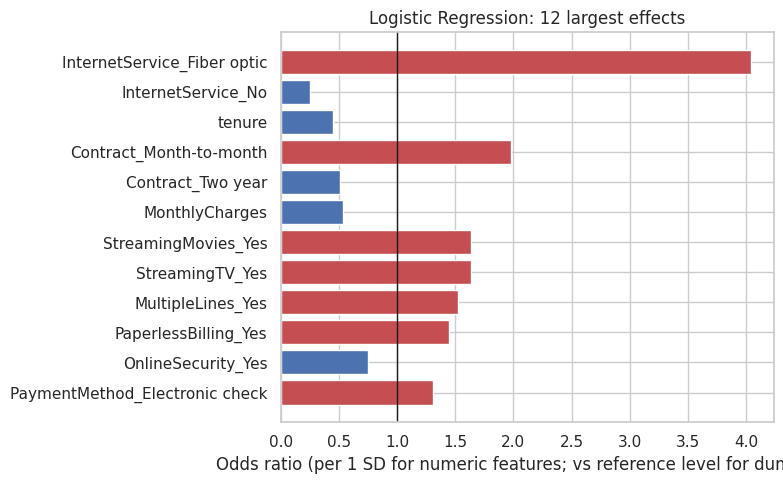

,odds ratio
PaymentMethod_Electronic check,1.31
OnlineSecurity_Yes,0.75
PaperlessBilling_Yes,1.45
MultipleLines_Yes,1.53
StreamingTV_Yes,1.63
StreamingMovies_Yes,1.63
MonthlyCharges,0.53
Contract_Two year,0.51
Contract_Month-to-month,1.98
tenure,0.45


In [63]:
lrm = models["Logistic Regression"]
names = lrm.named_steps["pre"].get_feature_names_out()
coef = pd.Series(lrm.named_steps["clf"].coef_[0], index=[n.split("__")[1] for n in names])
top = coef.reindex(coef.abs().sort_values(ascending=False).index)[:12][::-1]
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(top.index, np.exp(top.values), color=np.where(top.values > 0, "#C44E52", "#4C72B0")); ax.axvline(1, color="k", lw=1)
ax.set_xlabel("Odds ratio (per 1 SD for numeric features; vs reference level for dummies)"); ax.set_title("Logistic Regression: 12 largest effects")
save("fig11_logreg_odds_ratios")
display(np.exp(top).round(2).to_frame("odds ratio"))

Odds ratios (per 1 SD for numeric features). Fiber optic (4.0), month-to-month (2.0) and paperless billing (1.45) raise odds; tenure (0.45) and two-year contracts (0.51) lower them. **Caution:** `MonthlyCharges` has an odds ratio **below 1** here, although churners pay more on average. This is a collinearity/suppression effect: monthly charge is largely determined by the service dummies, so its coefficient only measures the effect of price *beyond* the services already in the model. Coefficients are not individually causal.

## Module 6: Error analysis and failure case

In [64]:
nm = "Logistic Regression (balanced)"
pred = (proba[nm] >= .5).astype(int)
t = X_test.assign(Churn=y_test.values, pred=pred)
ch = t[t.Churn == 1].assign(outcome=lambda d: np.where(d.pred == 1, "caught (TP)", "missed (FN)"))
prof = ch.groupby("outcome").agg(n=("Churn", "size"), median_tenure=("tenure", "median"), median_monthly=("MonthlyCharges", "median"),
                                 pct_month_to_month=("Contract", lambda s: (s == "Month-to-month").mean()),
                                 pct_fiber=("InternetService", lambda s: (s == "Fiber optic").mean()),
                                 pct_two_year=("Contract", lambda s: (s == "Two year").mean()))
display(prof.round(3)); prof.to_csv("outputs/error_analysis_profile.csv")
fn_models = {n: int(((proba[n] >= .5).astype(int) == 0)[y_test.values == 1].sum()) for n in show}
print("False negatives at threshold 0.5:", fn_models, "| total churners in test:", int(y_test.sum()))

,n,median_tenure,median_monthly,pct_month_to_month,pct_fiber,pct_two_year
outcome,,,,,,
caught (TP),291,6.0,79.15,0.973,0.780,0.000
missed (FN),83,30.0,56.70,0.554,0.301,0.108


False negatives at threshold 0.5: {'Logistic Regression': 170, 'KNN (K=81)': 156, 'Logistic Regression (balanced)': 83} | total churners in test: 374


We look at the churners the model misses. Caught churners are mostly new (median tenure 6 months), on month-to-month plans (97%) and fiber (78%). **Missed churners are different:** tenure 30 months, lower bills, 11% on two-year contracts. The model essentially never flags two-year customers, so it learns the "typical" churner and is blind to long-tenure, low-spend leavers.

### Business view (illustrative cost assumption)

In [65]:
C_CONTACT, C_LOSS = 1, 5
cost = results.assign(contacted=lambda d: d.TP + d.FP, expected_cost=lambda d: (d.TP + d.FP) * C_CONTACT + d.FN * C_LOSS)[
    ["model", "threshold", "recall", "precision", "contacted", "FN", "expected_cost"]]
cost.loc[len(cost)] = ["Contact nobody", np.nan, 0, np.nan, 0, int(y_test.sum()), int(y_test.sum()) * C_LOSS]
cost.loc[len(cost)] = ["Contact everyone", np.nan, 1, y_test.mean(), len(y_test), 0, len(y_test) * C_CONTACT]
display(cost.sort_values("expected_cost").round(3)); cost.to_csv("outputs/cost_analysis.csv", index=False)

,model,threshold,recall,precision,contacted,FN,expected_cost
6,KNN (K=81) @ recall>=0.80 threshold,0.309,0.805,0.499,603,73,968
2,Logistic Regression (balanced),0.500,0.778,0.509,572,83,987
4,Logistic Regression @ recall>=0.80 threshold,0.255,0.783,0.499,587,81,992
5,Logistic Regression (balanced) @ recall>=0.80 ...,0.495,0.778,0.504,577,83,992
3,KNN (K=81),0.500,0.583,0.588,371,156,1151
1,Logistic Regression,0.500,0.545,0.639,319,170,1169
8,Contact everyone,NaN,1.000,0.265,1409,0,1409
0,Majority-class baseline,0.500,0.000,0.000,0,374,1870
7,Contact nobody,NaN,0.000,NaN,0,374,1870


Assume a retention offer costs 1 unit and losing a churner costs 5 units (offers assumed effective). These numbers are an **assumption**, not data; replace them with real finance figures. Under this assumption every recall-oriented operating point beats the default 0.5 models and beats "contact everyone".

In [66]:
facts = {"rows": len(df), "churn_rate": float(y.mean()), "K_BEST": K_BEST, "chosen_features": NUMF + CATF, "dropped_cat": DROPPED_CAT,
         "test_overlap_share": float(overlap), "n_train": len(X_train), "n_test": len(X_test)}
json.dump(facts, open("outputs/key_facts.json", "w"), indent=2)
print(json.dumps(facts, indent=2))

{
  "rows": 7043,
  "churn_rate": 0.2653698707936959,
  "K_BEST": 81,
  "chosen_features": [
    "tenure",
    "MonthlyCharges",
    "Contract",
    "InternetService",
    "PaymentMethod",
    "PaperlessBilling",
    "OnlineSecurity",
    "Dependents",
    "TechSupport",
    "Partner",
    "SeniorCitizen",
    "OnlineBackup",
    "StreamingTV",
    "StreamingMovies",
    "DeviceProtection",
    "MultipleLines"
  ],
  "dropped_cat": [
    "gender",
    "PhoneService"
  ],
  "test_overlap_share": 0.009226401703335699,
  "n_train": 5634,
  "n_test": 1409
}


## Conclusions and recommendation
**Best model depends on business priority.**
* If the retention budget is tight and precision matters: **Logistic Regression at threshold 0.5** (precision 0.64, accuracy 0.80, but recall only 0.55, missing 170 of 374 churners).
* If missing a churner costs several times more than a wasted offer: use a **recall-oriented operating point**. LR balanced (recall 0.78, 83 missed) or KNN at the 0.31 threshold (recall 0.81, F1 0.62, lowest assumed cost). Differences between LR and KNN are within bootstrap noise (AUC 0.839 vs 0.833).
* **Recommended baseline:** Logistic Regression (balanced). It matches KNN on AUC, is transparent (odds ratios), cheap to retrain and needs no stored training set at prediction time.

**Actionable EDA insights**
1. Month-to-month customers churn at 42.7% vs 2.8% on two-year contracts; the first six months are riskiest (54% churn). Offer contract-upgrade incentives early in the customer life.
2. Fiber-optic (41.9%) and electronic-check (45.3%) customers churn most; investigate fiber service quality/pricing and nudge electronic-check users to automatic payment (15-17% churn).
3. Customers with tech support churn 15.2% vs 41.6% without; bundling support is worth testing in a controlled experiment.

**Prediction is not causation.** The model ranks customers by risk; it does not prove that a contract change or discount will reduce churn. Test interventions with an A/B experiment.

**Failure case / surprising findings:** (1) the default model reaches 80% accuracy yet misses 45% of churners, and even the balanced model catches none of the two-year-contract churners; (2) `MonthlyCharges` has a protective coefficient despite higher raw churn (collinearity); (3) the 11 blank `TotalCharges` rows are all new customers, not data errors.

**Limitations.** Single snapshot of one company, no time dimension (cannot validate on future data); no information on *why* people left or on competitor offers; the label has no observation window; 0.9% of test rows have a duplicate-profile twin in training (minor optimism); cost figures are illustrative; test set of 1,409 gives wide CIs (recall 95% CI about 0.49-0.60 for LR at 0.5).

**Possible leakage checked:** `customerID` dropped; no post-churn columns (e.g., churn reason) exist in this version; all learned transformations are inside pipelines fitted on the training data; thresholds and K chosen without the test set.